In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from math import sqrt
from itertools import product as iproduct

DATA_DIR = 'ROUND_3'
FIXED_FV = 5250
POSITION_LIMIT = 200

In [11]:
# Load days 1 and 2
dfs = []
for day in [1, 2]:
    df = pd.read_csv(f'{DATA_DIR}/prices_round_3_day_{day}.csv', sep=';')
    dfs.append(df)
raw = pd.concat(dfs, ignore_index=True)

vev = raw[raw['product'] == 'VELVETFRUIT_EXTRACT'].copy()
vev = vev[['day', 'timestamp', 'bid_price_1', 'ask_price_1', 'mid_price']].reset_index(drop=True)
vev['mid'] = vev['mid_price']
vev['global_tick'] = vev.index
print(f'Ticks: {len(vev)}  |  Day 1: {(vev.day==1).sum()}  |  Day 2: {(vev.day==2).sum()}')
vev.head()

Ticks: 20000  |  Day 1: 10000  |  Day 2: 10000


,day,timestamp,bid_price_1,ask_price_1,mid_price,mid,global_tick
0,1,0,5242,5248,5245.0,5245.0,0
1,1,100,5243,5248,5245.5,5245.5,1
2,1,200,5244,5249,5246.5,5246.5,2
3,1,300,5245,5250,5247.5,5247.5,3
4,1,400,5245,5250,5247.5,5247.5,4


In [12]:
def simulate_zscore_strategy(
    vev_df,
    fixed_fv=5250,
    z_window=75_000,
    z_warmup=3_000,
    z_entry=1.0,
    z_aggr=2.0,
    target_scale=5,
    misprice_thresh=4,
    aggr_thresh=30,
    limit=200,
    max_trade_per_tick=20,
):
    """
    Market-maker simulation (vectorized rolling stats for speed):
    - Fills at MID price (maker earns spread, not pays it)
    - z_entry gates z-score layer: only fires when |z| > z_entry
    - max_trade_per_tick models gradual passive queue fills (no instant target jumps)
    - Layer 1 (fixed FV) always active; Layer 2 (z-score) post-warmup only
    """
    mids = vev_df['mid'].values

    # Precompute rolling mean and std with pandas (fast, vectorized)
    s = pd.Series(mids)
    roll_mean = s.rolling(window=z_window, min_periods=1).mean().values
    roll_std  = np.maximum(1.0, s.rolling(window=z_window, min_periods=1).std(ddof=0).fillna(1.0).values)
    roll_n    = np.minimum(np.arange(1, len(mids)+1), z_window)
    z_arr     = (mids - roll_mean) / roll_std

    pos = 0
    cash = 0.0
    records = []

    for i, row in enumerate(vev_df.itertuples()):
        mid         = mids[i]
        rolling_mean = roll_mean[i]
        rolling_std  = roll_std[i]
        z            = z_arr[i]
        n            = roll_n[i]

        # Layer 1: fixed FV target (always)
        dev1    = mid - fixed_fv
        target1 = int(max(-limit, min(limit, -dev1 * target_scale)))

        # Layer 2: z-score target (post-warmup AND |z| > entry threshold)
        if n >= z_warmup and abs(z) > z_entry:
            target2 = int(max(-limit, min(limit, -z * target_scale)))
        else:
            target2 = target1

        combined_target = target2

        # Trade towards target at mid; cap per tick to model passive fills
        want    = combined_target - pos
        trade   = max(-max_trade_per_tick, min(max_trade_per_tick, want))
        trade   = max(-(limit + pos), min(limit - pos, trade))
        pos    += trade
        cash   -= trade * mid   # fill at mid — market maker assumption

        records.append({
            'day':          row.day,
            'timestamp':    row.timestamp,
            'mid':          mid,
            'rolling_mean': rolling_mean,
            'rolling_std':  rolling_std,
            'z':            z,
            'pos':          pos,
            'pnl':          cash + pos * mid,
            'in_warmup':    n < z_warmup,
            'target':       combined_target,
        })

    return pd.DataFrame(records)

In [13]:
# ── Sweep: different z_window values ──────────────────────────────────────────
windows = [5_000, 25_000, 50_000, 75_000, 'fixed_only']
results_window = {}

for w in windows:
    if w == 'fixed_only':
        # baseline: z_warmup > total ticks so never switches
        r = simulate_zscore_strategy(vev, z_window=75_000, z_warmup=999_999)
    else:
        r = simulate_zscore_strategy(vev, z_window=w, z_warmup=3_000)
    results_window[str(w)] = r
    final = r['pnl'].iloc[-1]
    d1 = r[r.day==1]['pnl'].iloc[-1]
    d2 = r[r.day==2]['pnl'].iloc[-1] - r[r.day==1]['pnl'].iloc[-1]
    print(f'window={str(w):>10}  total={final:>10,.0f}  day1={d1:>8,.0f}  day2={d2:>8,.0f}')

window=      5000  total=    18,712  day1=  15,738  day2=   2,974
window=     25000  total=    17,080  day1=  14,189  day2=   2,890
window=     50000  total=    17,080  day1=  14,189  day2=   2,890
window=     75000  total=    17,080  day1=  14,189  day2=   2,890
window=fixed_only  total=    58,794  day1=  31,190  day2=  27,604


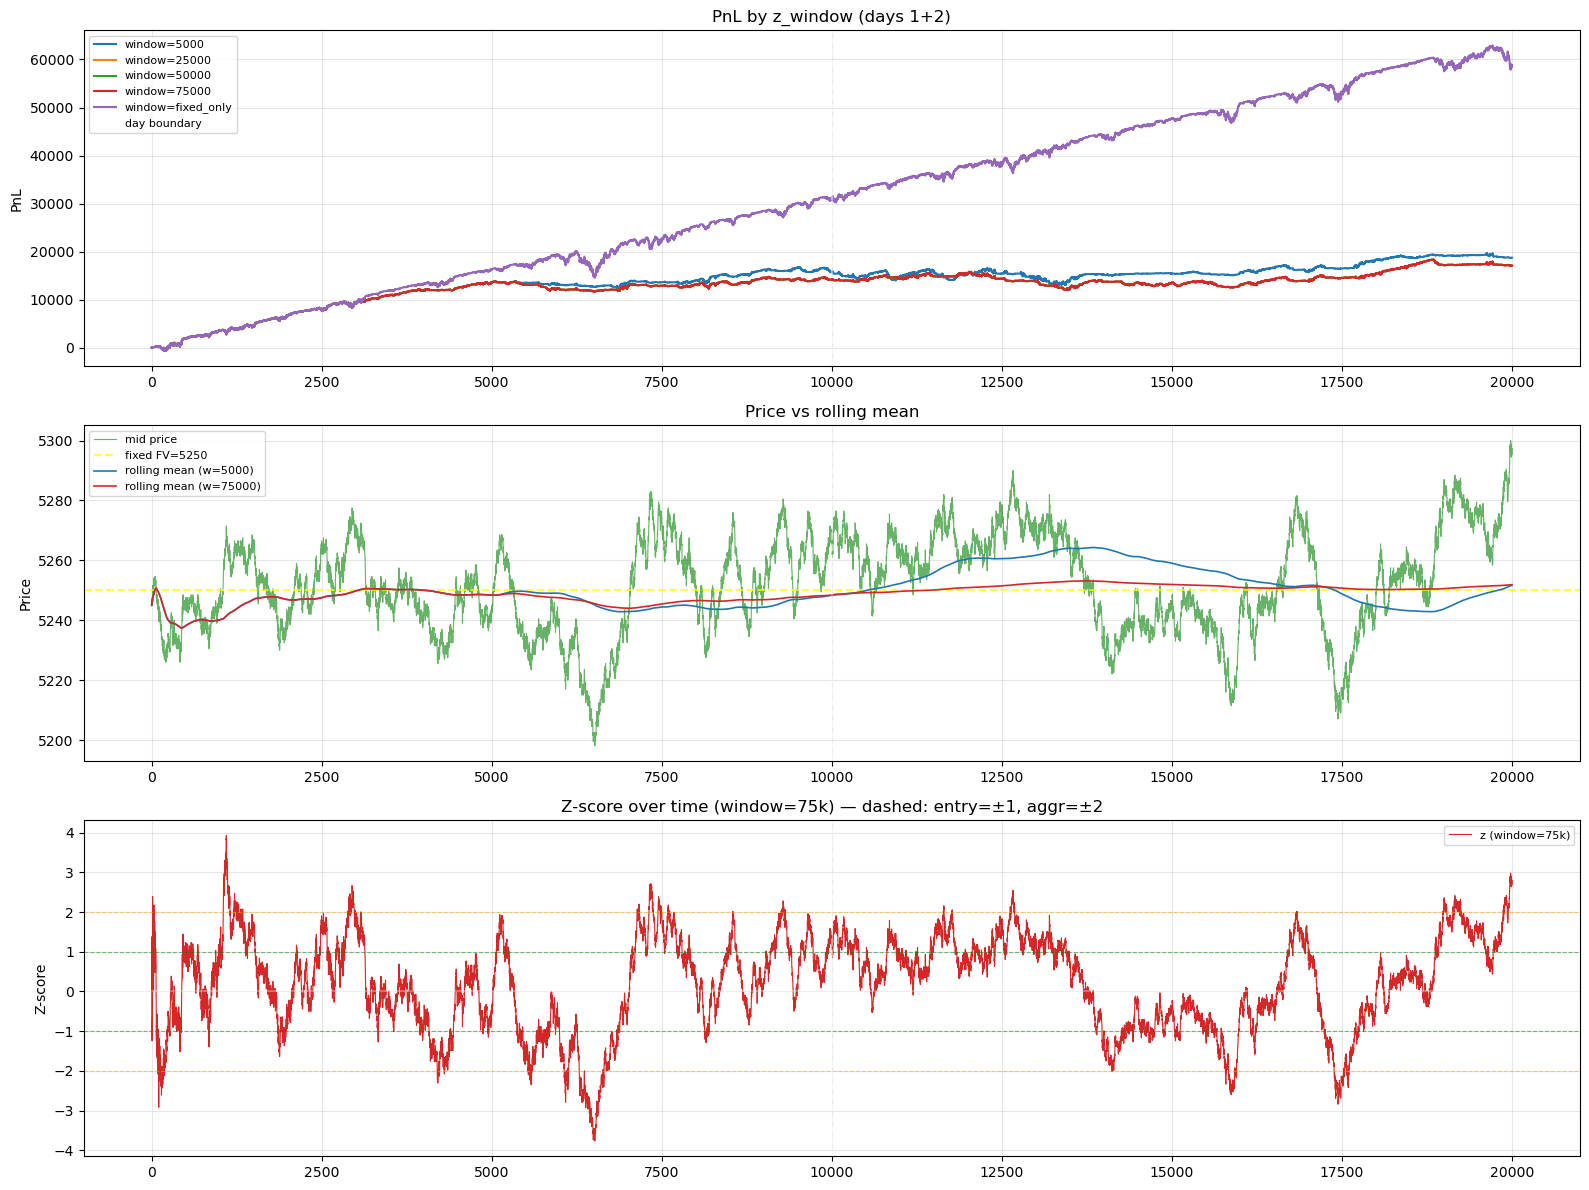

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=False)
colors = plt.cm.tab10.colors

# Plot 1: PnL curves
ax = axes[0]
for i, (label, r) in enumerate(results_window.items()):
    ax.plot(r.index, r['pnl'], label=f'window={label}', color=colors[i])
ax.axvline(x=(vev.day==1).sum(), color='white', linestyle='--', alpha=0.5, label='day boundary')
ax.set_title('PnL by z_window (days 1+2)')
ax.set_ylabel('PnL')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Plot 2: Rolling mean vs price for two windows
ax = axes[1]
r_ref = results_window['75000']
ax.plot(r_ref.index, r_ref['mid'], color='green', alpha=0.6, label='mid price', linewidth=0.8)
ax.axhline(FIXED_FV, color='yellow', linestyle='--', alpha=0.7, label=f'fixed FV={FIXED_FV}')
for w, c in [('5000', colors[0]), ('75000', colors[3])]:
    ax.plot(results_window[w].index, results_window[w]['rolling_mean'],
            label=f'rolling mean (w={w})', color=c, linewidth=1.2)
ax.axvline(x=(vev.day==1).sum(), color='white', linestyle='--', alpha=0.5)
ax.set_title('Price vs rolling mean')
ax.set_ylabel('Price')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Plot 3: Z-score over time for window=75k
ax = axes[2]
ax.plot(r_ref.index, r_ref['z'], color=colors[3], linewidth=0.8, label='z (window=75k)')
for thresh, col in [(1.0, 'green'), (2.0, 'orange'), (-1.0, 'green'), (-2.0, 'orange')]:
    ax.axhline(thresh, color=col, linestyle='--', alpha=0.5, linewidth=0.8)
ax.axhline(0, color='white', linestyle='-', alpha=0.3)
ax.axvline(x=(vev.day==1).sum(), color='white', linestyle='--', alpha=0.5)
ax.set_title('Z-score over time (window=75k) — dashed: entry=±1, aggr=±2')
ax.set_ylabel('Z-score')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
# ── Sweep: different z_entry thresholds ───────────────────────────────────────
entry_values = [0.5, 1.0, 1.5, 2.0, 2.5]
results_entry = {}

for e in entry_values:
    r = simulate_zscore_strategy(vev, z_window=75_000, z_warmup=3_000, z_entry=e, z_aggr=e*2)
    results_entry[str(e)] = r
    d1 = r[r.day==1]['pnl'].iloc[-1]
    d2 = r[r.day==2]['pnl'].iloc[-1] - r[r.day==1]['pnl'].iloc[-1]
    print(f'z_entry={e:.1f}  total={r["pnl"].iloc[-1]:>10,.0f}  day1={d1:>8,.0f}  day2={d2:>8,.0f}')

z_entry=0.5  total=    13,123  day1=  12,480  day2=     642
z_entry=1.0  total=    17,080  day1=  14,189  day2=   2,890
z_entry=1.5  total=    26,877  day1=  18,480  day2=   8,398
z_entry=2.0  total=    46,706  day1=  25,389  day2=  21,318
z_entry=2.5  total=    54,074  day1=  28,974  day2=  25,100


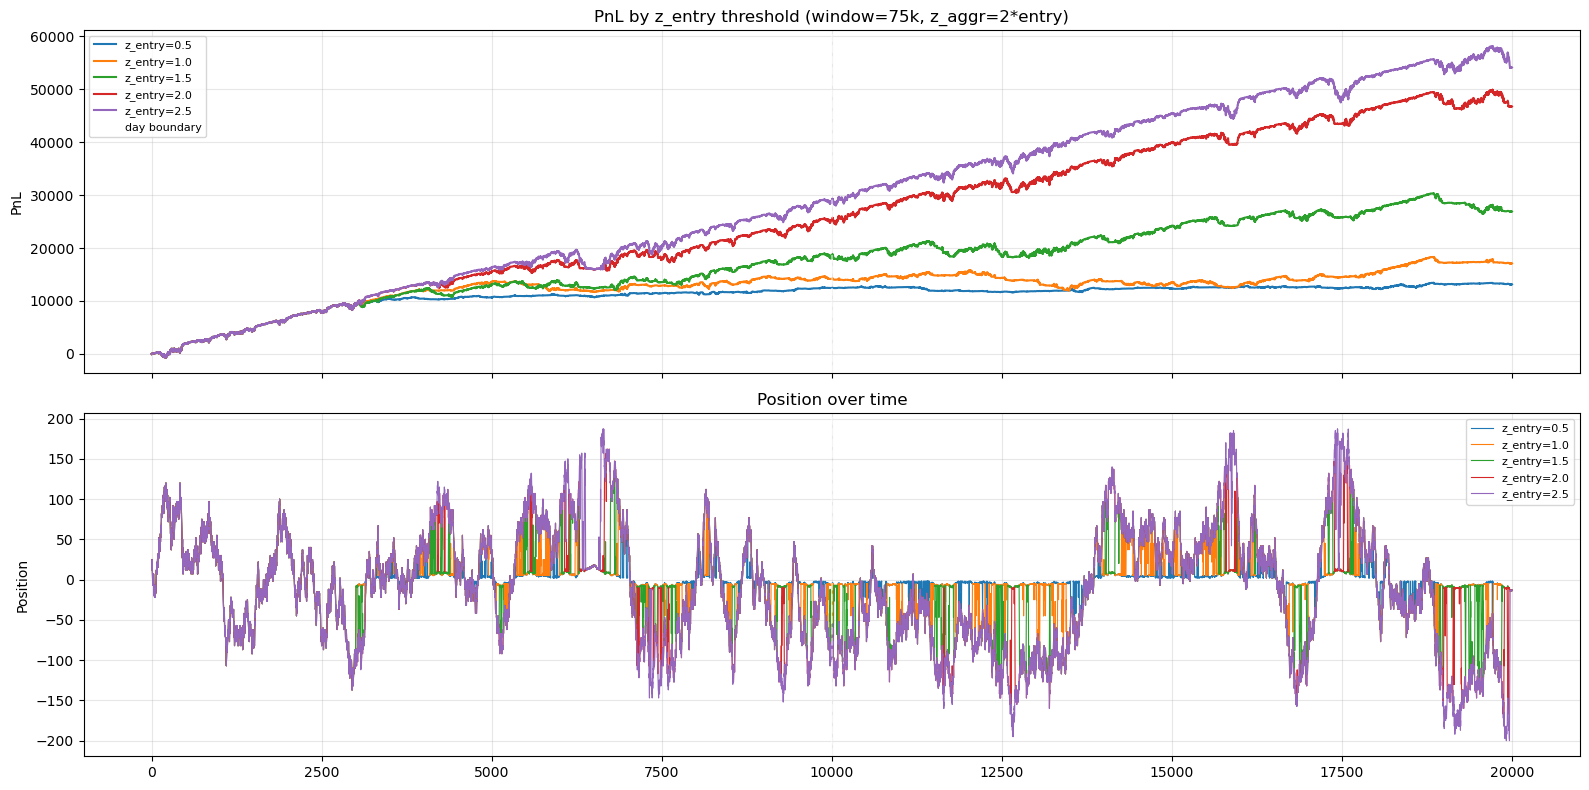

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

ax = axes[0]
for i, (label, r) in enumerate(results_entry.items()):
    ax.plot(r.index, r['pnl'], label=f'z_entry={label}', color=colors[i])
ax.axvline(x=(vev.day==1).sum(), color='white', linestyle='--', alpha=0.5, label='day boundary')
ax.set_title('PnL by z_entry threshold (window=75k, z_aggr=2*entry)')
ax.set_ylabel('PnL')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

ax = axes[1]
for i, (label, r) in enumerate(results_entry.items()):
    ax.plot(r.index, r['pos'], label=f'z_entry={label}', color=colors[i], linewidth=0.8)
ax.axvline(x=(vev.day==1).sum(), color='white', linestyle='--', alpha=0.5)
ax.set_title('Position over time')
ax.set_ylabel('Position')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

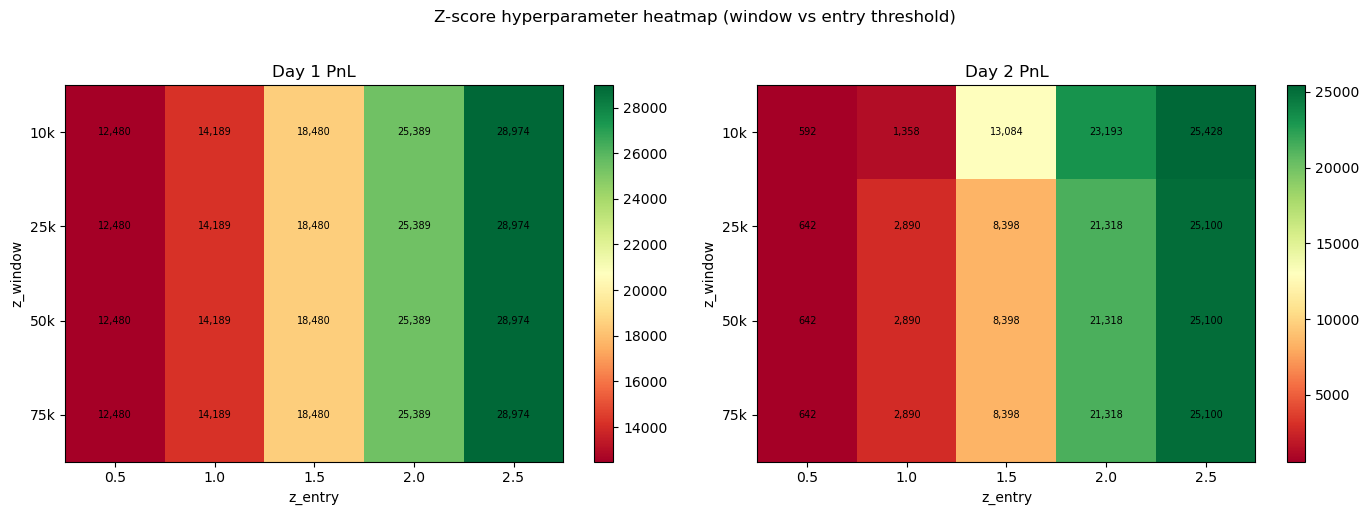

In [19]:
# ── Heatmap: z_window x z_entry on day2 PnL ───────────────────────────────────
windows_heat  = [10_000, 25_000, 50_000, 75_000]
entries_heat  = [0.5, 1.0, 1.5, 2.0, 2.5]
day1_boundary = (vev.day==1).sum()

d1_grid = np.zeros((len(windows_heat), len(entries_heat)))
d2_grid = np.zeros((len(windows_heat), len(entries_heat)))

for i, w in enumerate(windows_heat):
    for j, e in enumerate(entries_heat):
        r = simulate_zscore_strategy(vev, z_window=w, z_warmup=3_000, z_entry=e, z_aggr=e*2)
        d1_grid[i, j] = r[r.day==1]['pnl'].iloc[-1]
        d2_grid[i, j] = r[r.day==2]['pnl'].iloc[-1] - r[r.day==1]['pnl'].iloc[-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, grid, title in zip(axes, [d1_grid, d2_grid], ['Day 1 PnL', 'Day 2 PnL']):
    im = ax.imshow(grid, aspect='auto', cmap='RdYlGn')
    ax.set_xticks(range(len(entries_heat)))
    ax.set_xticklabels([str(e) for e in entries_heat])
    ax.set_yticks(range(len(windows_heat)))
    ax.set_yticklabels([f'{w//1000}k' for w in windows_heat])
    ax.set_xlabel('z_entry')
    ax.set_ylabel('z_window')
    ax.set_title(title)
    plt.colorbar(im, ax=ax)
    for ii in range(len(windows_heat)):
        for jj in range(len(entries_heat)):
            ax.text(jj, ii, f'{grid[ii,jj]:,.0f}', ha='center', va='center', fontsize=7)

plt.suptitle('Z-score hyperparameter heatmap (window vs entry threshold)', y=1.02)
plt.tight_layout()
plt.show()

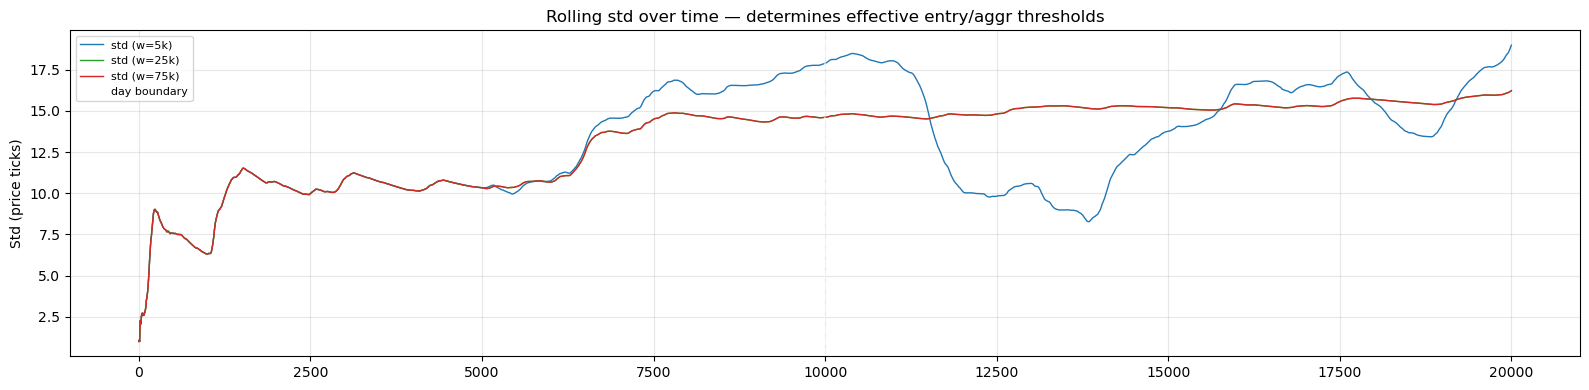

Window=75k  |  mean std: 13.34  |  effective entry thresh: 13.34 (z_entry=1.0)


In [18]:
# ── Rolling std over time — shows how volatile VEV is across windows ───────────
fig, ax = plt.subplots(figsize=(16, 4))
for w, c in zip([5_000, 25_000, 75_000], [colors[0], colors[2], colors[3]]):
    r = results_window[str(w)]
    ax.plot(r.index, r['rolling_std'], label=f'std (w={w//1000}k)', color=c, linewidth=1)
ax.axvline(x=(vev.day==1).sum(), color='white', linestyle='--', alpha=0.5, label='day boundary')
ax.set_title('Rolling std over time — determines effective entry/aggr thresholds')
ax.set_ylabel('Std (price ticks)')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Print summary stats
r75 = results_window['75000']
print(f'Window=75k  |  mean std: {r75["rolling_std"].mean():.2f}  '
      f'|  effective entry thresh: {1.0 * r75["rolling_std"].mean():.2f} '
      f'(z_entry=1.0)')